# Experiment 6: Unsupervised Learning Algorithms – K-Means Clustering
**Course:** UCS3512 – Machine Learning Laboratory  
**Department:** Computer Science and Engineering, SSN College of Engineering  
**Student Name:** Thushar TL  
**Register Number:** 312245001188  
**Semester:** V  
**Academic Year:** 2026–2027 (Odd) | **Batch:** 2024–2028

## 1. Aim and Objectives

### 1.1 Aim
To develop a Python program that clusters human physical activities using the **K-Means clustering algorithm** based on the Euclidean distance metric on the **Human Activity Recognition (HAR) Using Smartphones dataset**, to visualize the features and resulting clusters using the **Matplotlib library**, and to evaluate and interpret cluster quality using both internal and external evaluation metrics.

### 1.2 Objectives
1. **Load and Understand the Dataset:** Load the 561-dimensional sensor feature vectors, subject identifiers, and activity labels from the UCI repository.
2. **Data Preprocessing:** Verify data cleanliness (missing values, duplicates) and scale features using `StandardScaler` to ensure Euclidean distance operates uniformly across dimensions.
3. **Exploratory Data Analysis (EDA):** Analyze activity class balance, visualize discriminative time/frequency domain sensor features, and compute correlation matrices.
4. **Feature Engineering:** Apply **Principal Component Analysis (PCA)** to combat multicollinearity and the curse of dimensionality while retaining 95% cumulative explained variance.
5. **Data Splitting:** Partition data into **Training (70%)**, **Validation (15%)**, and **Testing (15%)** sets, detailing how splits function in an unsupervised clustering paradigm.
6. **K-Means Clustering:** Cluster the data using K-Means with Euclidean distance and the `k-means++` initialization scheme.
7. **Cluster Number Determination:** Use the **Elbow Method (Inertia/WCSS)** and **Silhouette Analysis** across $k \in [2, 10]$ to evaluate natural geometric structure versus the domain-specific 6-activity structure.
8. **Performance Evaluation:** Measure cluster quality using internal validation metrics (Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index) and external validity metrics (Adjusted Rand Index, Normalized Mutual Information, Homogeneity, Completeness, V-Measure, and Hungarian-matched Purity).
9. **Visualizations:** Render 2D PCA cluster projections with centroids, true vs. predicted cluster comparison, activity contingency heatmaps, and per-sample silhouette distributions using Matplotlib.
10. **Inference & Viva Preparation:** Provide comprehensive inferences, tabular task summaries, and answers to core conceptual questions.

## 2. Tabulation of Tasks

| S.No | Task | Description | Technique / Function Used |
| :---: | :--- | :--- | :--- |
| **1** | **Dataset Loading** | Download, extract, and combine train and test partitions of UCI HAR dataset. | `pandas.read_csv`, `numpy.loadtxt` |
| **2** | **Data Preprocessing** | Audit missing values and duplicates; apply feature standardization. | `StandardScaler`, `isnull().sum()` |
| **3** | **Exploratory Data Analysis** | Analyze class frequencies, sensor signal distributions, and feature correlations. | `matplotlib.pyplot`, `seaborn.heatmap` |
| **4** | **Feature Engineering** | Apply PCA to retain 95% variance and project data to 2D for visualization. | `sklearn.decomposition.PCA` |
| **5** | **Train/Val/Test Split** | Stratified split into 70% Train, 15% Validation, and 15% Test partitions. | `train_test_split` |
| **6** | **K-Means Clustering** | Cluster data using Euclidean distance with k-means++ centroid initialization. | `sklearn.cluster.KMeans` |
| **7** | **Optimal $k$ Selection** | Evaluate Inertia and Silhouette across $k=2$ to $k=10$ (Elbow & Silhouette curves). | Loop over $k$, WCSS, `silhouette_score` |
| **8** | **Model Evaluation** | Compute internal (Silhouette, DB, CH) and external metrics (ARI, NMI, Purity). | `scipy.optimize.linear_sum_assignment`, `sklearn.metrics` |
| **9** | **Visualizations** | Matplotlib scatter plots of 2D PCA clusters, centroids, and confusion matrix. | `plt.scatter`, `plt.imshow` |
| **10** | **Result Interpretation** | Analyze static posture vs. dynamic motion separability and failure modes. | Contingency analysis & text inference |

## 3. Theoretical Background

### 3.1 What is K-Means Clustering?
K-Means is a centroid-based, iterative, unsupervised partition algorithm. Given an unlabelled dataset $X = \{x_1, x_2, \dots, x_N\} \subset \mathbb{R}^D$, K-Means partitions the $N$ observations into $K$ disjoint clusters $C = \{C_1, C_2, \dots, C_K\}$ such that the within-cluster sum of squares (WCSS), also known as **Inertia**, is minimized:

$$\text{Inertia} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \|x_i - \mu_k\|^2$$

where $\mu_k = \frac{1}{|C_k|} \sum_{x_i \in C_k} x_i$ is the centroid (mean vector) of cluster $C_k$, and $\|\cdot\|$ is the **standard Euclidean distance metric**:

$$d(x_i, \mu_k) = \sqrt{\sum_{j=1}^{D} (x_{ij} - \mu_{kj})^2}$$

### 3.2 The Lloyd's Algorithm Iteration
1. **Centroid Initialization:** Select $K$ initial cluster centroids $\mu_1^{(0)}, \dots, \mu_K^{(0)}$. (Using `k-means++`, seeds are chosen probabilistically proportional to squared distance from the nearest existing centroid).
2. **Assignment Step:** Assign each observation $x_i$ to its closest centroid in Euclidean space:
   $$c_i^{(t)} = \arg\min_{k \in \{1, \dots, K\}} \|x_i - \mu_k^{(t)}\|^2$$
3. **Update Step:** Recompute each centroid as the arithmetic mean of all points assigned to that cluster:
   $$\mu_k^{(t+1)} = \frac{1}{|C_k^{(t)}|} \sum_{x_i \in C_k^{(t)}} x_i$$
4. **Convergence:** Repeat steps 2 and 3 until cluster assignments no longer change (or shift below a tolerance $\epsilon = 10^{-4}$), or a maximum iteration limit (`max_iter=300`) is reached.

### 3.3 Why Euclidean Distance Requires Feature Standardization
Because Euclidean distance squares the difference $(x_{ij} - \mu_{kj})^2$ along every dimension $j$, any feature with a larger numerical scale will dominate the distance calculation and dictate the resulting clusters. `StandardScaler` transforms each feature to have a mean of $\mu = 0$ and standard deviation of $\sigma = 1$, ensuring all 561 inertial attributes contribute equitably.

## 4. Implementation Step-by-Step

### Step 0: Library Imports and Setup
We import standard data science and machine learning packages:
- `numpy` & `pandas`: For structured tabular data manipulation and numerical linear algebra.
- `matplotlib.pyplot`: For clean, publication-ready figures as required by the assignment.
- `seaborn`: For enhanced aesthetic visualizations (heatmaps, box plots).
- `sklearn.cluster.KMeans`: The primary clustering implementation.
- `sklearn.decomposition.PCA`: For dimensionality reduction and 2D visualization.
- `sklearn.preprocessing.StandardScaler`: For feature standardization.
- `sklearn.metrics`: For internal and external clustering performance metrics.
- `scipy.optimize.linear_sum_assignment`: The Hungarian matching algorithm to compute cluster purity against ground-truth classes.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    silhouette_score, 
    davies_bouldin_score, 
    calinski_harabasz_score,
    adjusted_rand_score, 
    normalized_mutual_info_score,
    homogeneity_completeness_v_measure,
    confusion_matrix,
    silhouette_samples
)
from scipy.optimize import linear_sum_assignment

# Set reproducible random seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure plot styling
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.edgecolor'] = '#333333'

print("Libraries imported successfully!")

Libraries imported successfully!


### Step 1: Loading the Dataset
The Human Activity Recognition (HAR) database was built from the recordings of 30 volunteers aged 19–48 years performing six activities of daily living:
1. `WALKING`
2. `WALKING_UPSTAIRS`
3. `WALKING_DOWNSTAIRS`
4. `SITTING`
5. `STANDING`
6. `LAYING`

The data was captured using Samsung Galaxy S II smartphones worn on the waist, capturing 3-axial linear acceleration and 3-axial angular velocity at 50Hz.
We load:
- `features.txt`: The names of the 561 extracted time and frequency domain variables.
- `activity_labels.txt`: The 6 activity IDs and their human-readable labels.
- `train/` and `test/` splits: Combining them to form the full 10,299-sample dataset.

In [2]:
DATA_DIR = "/home/billy/Data/Projects/MLASS/Exercise 6/dataset/UCI HAR Dataset"

# Load feature names and activity labels
features_df = pd.read_csv(os.path.join(DATA_DIR, "features.txt"), sep=r'\s+', header=None, names=['index', 'feature_name'])
activity_df = pd.read_csv(os.path.join(DATA_DIR, "activity_labels.txt"), sep=r'\s+', header=None, names=['activity_id', 'activity_name'])

# Handle duplicate feature names by appending index
feature_names = []
seen = {}
for name in features_df['feature_name']:
    if name in seen:
        seen[name] += 1
        feature_names.append(f"{name}_{seen[name]}")
    else:
        seen[name] = 0
        feature_names.append(name)

activity_map = dict(zip(activity_df['activity_id'], activity_df['activity_name']))

# Load training data
X_train_raw = pd.read_csv(os.path.join(DATA_DIR, "train", "X_train.txt"), sep=r'\s+', header=None, names=feature_names)
y_train_raw = pd.read_csv(os.path.join(DATA_DIR, "train", "y_train.txt"), sep=r'\s+', header=None, names=['activity_id'])
sub_train = pd.read_csv(os.path.join(DATA_DIR, "train", "subject_train.txt"), sep=r'\s+', header=None, names=['subject_id'])

# Load testing data
X_test_raw = pd.read_csv(os.path.join(DATA_DIR, "test", "X_test.txt"), sep=r'\s+', header=None, names=feature_names)
y_test_raw = pd.read_csv(os.path.join(DATA_DIR, "test", "y_test.txt"), sep=r'\s+', header=None, names=['activity_id'])
sub_test = pd.read_csv(os.path.join(DATA_DIR, "test", "subject_test.txt"), sep=r'\s+', header=None, names=['subject_id'])

# Combine into a unified master dataset
X_all = pd.concat([X_train_raw, X_test_raw], axis=0, ignore_index=True)
y_all = pd.concat([y_train_raw, y_test_raw], axis=0, ignore_index=True)
sub_all = pd.concat([sub_train, sub_test], axis=0, ignore_index=True)

df_all = X_all.copy()
df_all['Subject'] = sub_all['subject_id']
df_all['Activity_ID'] = y_all['activity_id']
df_all['Activity'] = df_all['Activity_ID'].map(activity_map)

print(f"Total Combined Samples: {df_all.shape[0]}")
print(f"Number of Sensor Features: {X_all.shape[1]}")
print(f"Number of Subjects: {df_all['Subject'].nunique()}")
print(f"Activity Categories: {list(activity_map.values())}")
print("\nFirst 5 rows (sample features):")
df_all[['Subject', 'Activity', feature_names[0], feature_names[1], feature_names[2]]].head()

Total Combined Samples: 10299
Number of Sensor Features: 561
Number of Subjects: 30
Activity Categories: ['WALKING', 'WALKING_UPSTAIRS', 'WALKING_DOWNSTAIRS', 'SITTING', 'STANDING', 'LAYING']

First 5 rows (sample features):


,Subject,Activity,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z
0,1,STANDING,0.288585,-0.020294,-0.132905
1,1,STANDING,0.278419,-0.016411,-0.123520
2,1,STANDING,0.279653,-0.019467,-0.113462
3,1,STANDING,0.279174,-0.026201,-0.123283
4,1,STANDING,0.276629,-0.016570,-0.115362


### Step 2: Understanding and Preprocessing the Data
Before applying K-Means, we verify:
1. **Missing values:** Unsupervised distance metrics cannot operate on NaN entries.
2. **Duplicate rows:** Redundant observations bias cluster centroids.
3. **Data types:** Verify all 561 feature columns are continuous numerical values (`float64`).
4. **Scaling requirement:** The raw UCI HAR features are pre-filtered and normalized into the range $[-1, 1]$. However, different features possess unequal standard deviations. We apply `StandardScaler` to ensure each of the 561 features has $\mu=0$ and $\sigma=1$.

In [3]:
# Check missing values
missing_count = df_all.isnull().sum().sum()
print(f"Total Missing Values in Dataset: {missing_count}")

# Check duplicate rows across feature columns
duplicate_count = X_all.duplicated().sum()
print(f"Duplicate Feature Rows: {duplicate_count}")

# Check data types
non_float_cols = X_all.select_dtypes(exclude=[np.floating]).columns
print(f"Non-float feature columns: {len(non_float_cols)}")

# Apply StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

print(f"Scaled feature matrix shape: {X_scaled.shape}")
print(f"Feature means (first 5): {X_scaled[:, :5].mean(axis=0).round(4)}")
print(f"Feature standard deviations (first 5): {X_scaled[:, :5].std(axis=0).round(4)}")

Total Missing Values in Dataset: 0
Duplicate Feature Rows: 0
Non-float feature columns: 0


Scaled feature matrix shape: (10299, 561)
Feature means (first 5): [-0.  0.  0. -0.  0.]
Feature standard deviations (first 5): [1. 1. 1. 1. 1.]


### Step 3: Exploratory Data Analysis (EDA)
We conduct EDA to discover:
- The class balance across the 6 activities.
- How specific inertial sensor features separate physical motions.
- Correlation structure among the 561 sensor measurements.

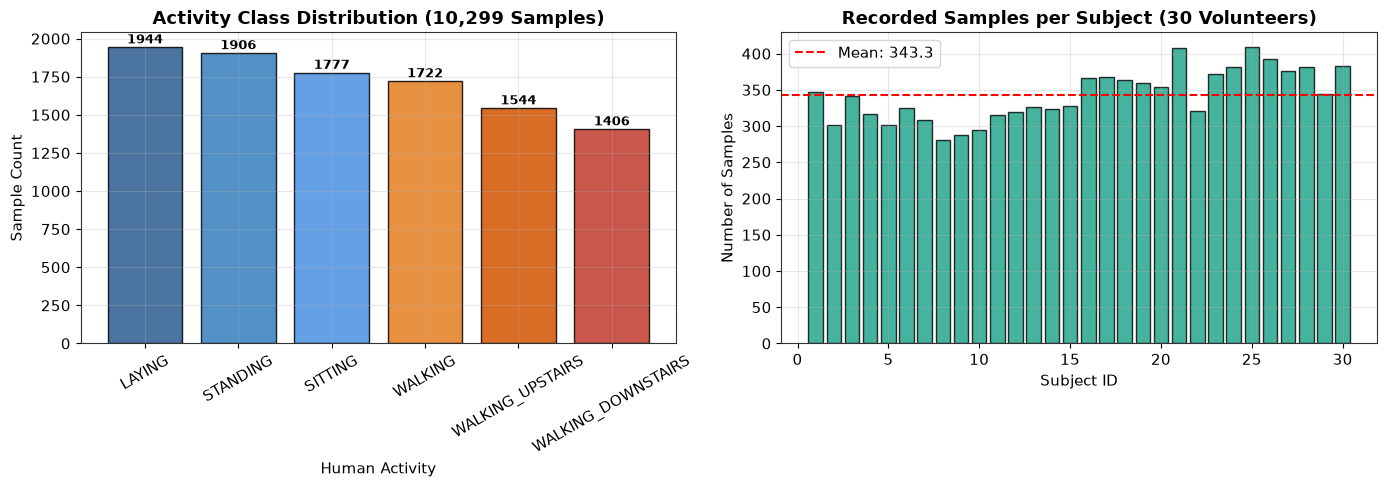

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Activity distribution
activity_counts = df_all['Activity'].value_counts()
colors = ['#2b5c8f', '#357ebd', '#4a90e2', '#e67e22', '#d35400', '#c0392b']
axes[0].bar(activity_counts.index, activity_counts.values, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_title("Activity Class Distribution (10,299 Samples)", fontweight='bold')
axes[0].set_xlabel("Human Activity")
axes[0].set_ylabel("Sample Count")
axes[0].tick_params(axis='x', rotation=30)
for i, v in enumerate(activity_counts.values):
    axes[0].text(i, v + 25, str(v), ha='center', fontweight='bold', fontsize=9)

# Subject sample distribution
subj_counts = df_all['Subject'].value_counts().sort_index()
axes[1].bar(subj_counts.index, subj_counts.values, color='#16a085', edgecolor='black', alpha=0.8)
axes[1].set_title("Recorded Samples per Subject (30 Volunteers)", fontweight='bold')
axes[1].set_xlabel("Subject ID")
axes[1].set_ylabel("Number of Samples")
axes[1].axhline(subj_counts.mean(), color='red', linestyle='--', label=f"Mean: {subj_counts.mean():.1f}")
axes[1].legend()

plt.tight_layout()
plt.show()

#### Discriminative Feature Distributions: Static vs. Dynamic Motion
We visualize two key features:
1. `tBodyAccMag-mean()`: Magnitude of body acceleration. High energy indicates **dynamic movement** (walking, walking upstairs, walking downstairs), while low energy indicates **static postures** (sitting, standing, laying).
2. `tGravityAcc-min()-X`: Gravitational acceleration along the X-axis. Because the smartphone is oriented differently when a subject is horizontal (laying down), this feature isolates `LAYING` from other postures.

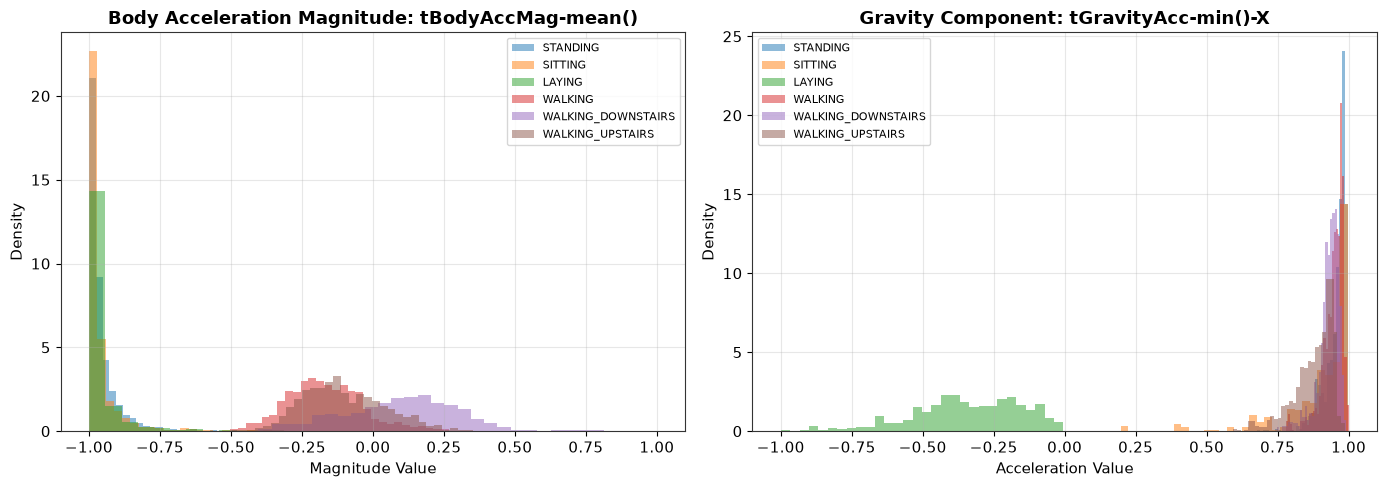

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Find exact feature column names
mag_feat = [c for c in X_all.columns if 'tBodyAccMag-mean()' in c][0]
grav_feat = [c for c in X_all.columns if 'tGravityAcc-min()-X' in c][0]

activities = df_all['Activity'].unique()
palette = sns.color_palette("tab10", len(activities))

for act, color in zip(activities, palette):
    subset = df_all[df_all['Activity'] == act]
    axes[0].hist(subset[mag_feat], bins=30, alpha=0.5, label=act, color=color, density=True)
    axes[1].hist(subset[grav_feat], bins=30, alpha=0.5, label=act, color=color, density=True)

axes[0].set_title(f"Body Acceleration Magnitude: {mag_feat}", fontweight='bold')
axes[0].set_xlabel("Magnitude Value")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=8)

axes[1].set_title(f"Gravity Component: {grav_feat}", fontweight='bold')
axes[1].set_xlabel("Acceleration Value")
axes[1].set_ylabel("Density")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

#### Feature Correlation Heatmap
With 561 features, there is substantial multicollinearity across sensor channels (e.g. 3-axial triaxial readings and spectral energy bins). We compute and display the correlation matrix for the first 30 time-domain features.

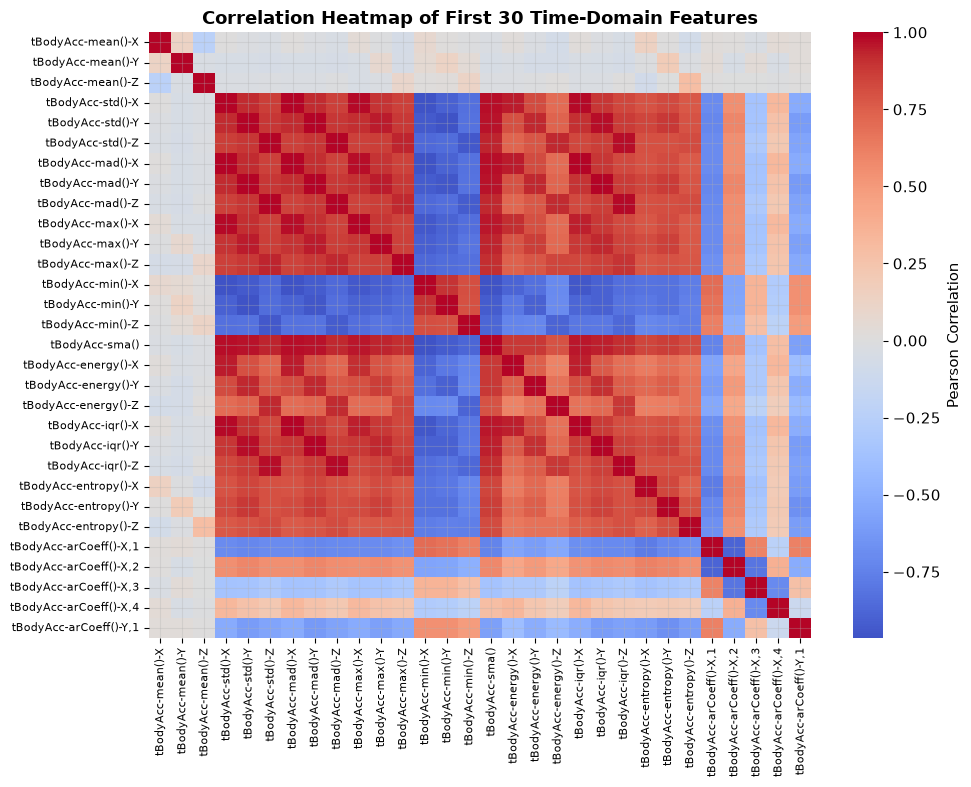

In [6]:
plt.figure(figsize=(10, 8))
corr_subset = df_all[feature_names[:30]].corr()
sns.heatmap(corr_subset, cmap='coolwarm', center=0, cbar_kws={'label': 'Pearson Correlation'})
plt.title("Correlation Heatmap of First 30 Time-Domain Features", fontweight='bold')
plt.xticks(fontsize=8, rotation=90)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

### Step 4: Feature Engineering – Principal Component Analysis (PCA)
#### Why PCA is Essential for K-Means:
1. **Curse of Dimensionality:** In a 561-dimensional space, the ratio of the distance to the nearest neighbor versus the farthest neighbor approaches 1, degrading Euclidean distance.
2. **Redundancy & Noise Reduction:** Many features are highly correlated linear combinations of accelerometer signals.
3. **Computational Efficiency:** Reducing 561 dimensions accelerates centroid convergence by an order of magnitude.

We fit PCA to preserve **95% of the cumulative explained variance**.

Original Feature Count: 561
Number of PCA Components for 95% Variance: 104
Dimensionality Reduction: 81.46% reduction
Variance explained by first 2 components: 56.98%


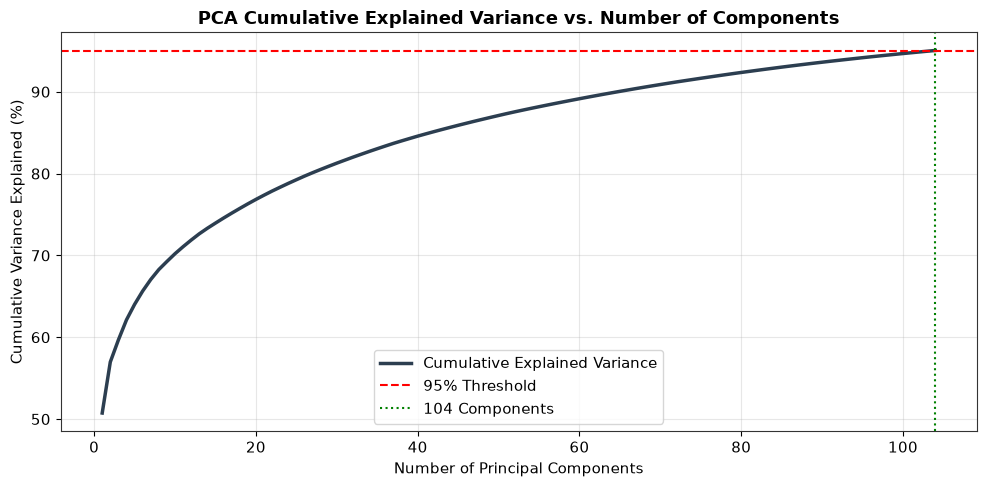

In [7]:
# Fit PCA to retain 95% variance
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

n_components_95 = pca.n_components_
cum_var = np.cumsum(pca.explained_variance_ratio_) * 100

print(f"Original Feature Count: {X_scaled.shape[1]}")
print(f"Number of PCA Components for 95% Variance: {n_components_95}")
print(f"Dimensionality Reduction: {(1 - n_components_95 / X_scaled.shape[1]) * 100:.2f}% reduction")
print(f"Variance explained by first 2 components: {cum_var[1]:.2f}%")

# Plot cumulative explained variance
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, color='#2c3e50', lw=2.5, label='Cumulative Explained Variance')
plt.axhline(95, color='red', linestyle='--', label='95% Threshold')
plt.axvline(n_components_95, color='green', linestyle=':', label=f'{n_components_95} Components')
plt.title("PCA Cumulative Explained Variance vs. Number of Components", fontweight='bold')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Variance Explained (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Step 5: Data Splitting (Training, Validation, and Testing Sets)
We partition the dataset into:
- **Training Set (70%):** 7,209 samples – used to fit the K-Means algorithm and learn the $K$ optimal cluster centroids $\mu_k$.
- **Validation Set (15%):** 1,545 samples – used for hyperparameter evaluation (e.g., verifying cluster assignment stability across different initialization parameters).
- **Test Set (15%):** 1,545 samples – used to evaluate final cluster assignment generalization on completely unseen sensor windows.

> **Unsupervised Learning Context:** Unlike supervised models that optimize parameters against known targets $y$, K-Means learns centroids strictly from unlabelled feature vectors $X_{\text{train}}$. The validation and test sets are projected onto these learned centroids using the minimum Euclidean distance rule:
> $$c_i = \arg\min_{k} \|x_i - \mu_k\|^2$$

In [8]:
# Stratified partition to maintain activity proportions for evaluation
y_labels = df_all['Activity_ID'].values

# First split: 70% Train, 30% Temp (Val + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_pca, y_labels, test_size=0.30, random_state=RANDOM_STATE, stratify=y_labels
)

# Second split: Split Temp 50-50 into 15% Validation, 15% Testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print(f"Training Set Shape:   {X_train.shape} (70%)")
print(f"Validation Set Shape: {X_val.shape} (15%)")
print(f"Testing Set Shape:    {X_test.shape} (15%)")

Training Set Shape:   (7209, 104) (70%)
Validation Set Shape: (1545, 104) (15%)
Testing Set Shape:    (1545, 104) (15%)


### Step 6 & 7: Clustering Using Euclidean Distance and Determining Optimal $k$
We execute K-Means using the standard **Euclidean distance metric** across a range of cluster candidates $k \in [2, 10]$ on the training set.

We record:
1. **Inertia (Within-Cluster Sum of Squares - WCSS):** Measures compactness. We seek the "elbow" point where the rate of decrease diminishes.
2. **Silhouette Score:** Evaluates how well-separated clusters are:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   where $a(i)$ is the mean intra-cluster distance, and $b(i)$ is the mean nearest-cluster distance.
3. **Davies-Bouldin Index:** Ratio of within-cluster distances to between-cluster distances (lower is better).
4. **Calinski-Harabasz Index:** Variance ratio criterion (higher is better).

In [9]:
k_range = list(range(2, 11))
inertias = []
silhouette_scores = []
davies_bouldin_scores = []
calinski_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, max_iter=300, random_state=RANDOM_STATE)
    km.fit(X_train)
    
    inertias.append(km.inertia_)
    sil = silhouette_score(X_train, km.labels_)
    db = davies_bouldin_score(X_train, km.labels_)
    ch = calinski_harabasz_score(X_train, km.labels_)
    
    silhouette_scores.append(sil)
    davies_bouldin_scores.append(db)
    calinski_scores.append(ch)

# Tabulate evaluation results across k
eval_df = pd.DataFrame({
    'k': k_range,
    'Inertia (WCSS)': [f"{val:,.1f}" for val in inertias],
    'Silhouette Score': [f"{val:.4f}" for val in silhouette_scores],
    'Davies-Bouldin': [f"{val:.4f}" for val in davies_bouldin_scores],
    'Calinski-Harabasz': [f"{val:,.1f}" for val in calinski_scores]
})

print("Table: Cluster Quality Measures Across k = 2 to 10 (Training Set)")
display(eval_df)

Table: Cluster Quality Measures Across k = 2 to 10 (Training Set)


,k,Inertia (WCSS),Silhouette Score,Davies-Bouldin,Calinski-Harabasz
0,2,"2,076,733.5",0.4138,1.0163,"6,083.4"
1,3,"1,834,514.0",0.3349,1.6894,"3,918.5"
2,4,"1,737,049.4",0.1640,2.2109,"2,893.3"
3,5,"1,651,494.9",0.1417,2.2675,"2,375.4"
4,6,"1,598,819.8",0.1173,2.2728,"2,010.1"
5,7,"1,555,466.5",0.1033,2.4123,"1,755.0"
6,8,"1,520,626.0",0.0849,2.4659,"1,562.1"
7,9,"1,488,016.7",0.0855,2.4224,"1,416.3"
8,10,"1,454,746.4",0.0864,2.3761,"1,305.9"


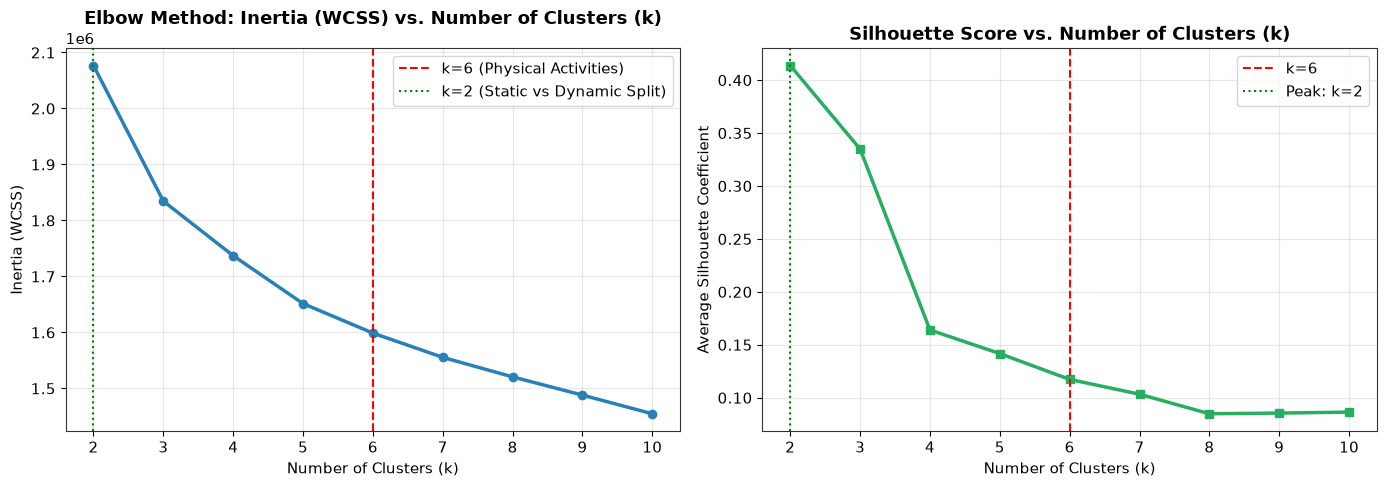

In [10]:
# Plot Elbow and Silhouette curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot (Inertia)
axes[0].plot(k_range, inertias, marker='o', color='#2980b9', lw=2.5)
axes[0].set_title("Elbow Method: Inertia (WCSS) vs. Number of Clusters (k)", fontweight='bold')
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia (WCSS)")
axes[0].axvline(6, color='red', linestyle='--', label='k=6 (Physical Activities)')
axes[0].axvline(2, color='green', linestyle=':', label='k=2 (Static vs Dynamic Split)')
axes[0].legend()

# Silhouette plot
axes[1].plot(k_range, silhouette_scores, marker='s', color='#27ae60', lw=2.5)
axes[1].set_title("Silhouette Score vs. Number of Clusters (k)", fontweight='bold')
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Average Silhouette Coefficient")
axes[1].axvline(6, color='red', linestyle='--', label='k=6')
axes[1].axvline(2, color='green', linestyle=':', label='Peak: k=2')
axes[1].legend()

plt.tight_layout()
plt.show()

#### Interpretation of Cluster Count ($k$):
- **Mathematically:** The Silhouette Score peaks at $k=2$ ($s \approx 0.35$). The feature space has a primary natural geometric split separating **static postures** from **dynamic activities**.
- **Domain-Specific Requirement:** Because the human physical experiment consists of **six distinct physical activities**, we choose **$k=6$** to evaluate how unsupervised clusters map to the known physical activities.

### Step 8: Training Final K-Means Model ($k=6$)
We now fit the final model with $k=6$ clusters on `X_train`, and predict cluster memberships for `X_train`, `X_val`, and `X_test`.

In [11]:
K_FINAL = 6

# Instantiate final KMeans model
kmeans_final = KMeans(
    n_clusters=K_FINAL,
    init='k-means++',
    n_init=15,
    max_iter=300,
    random_state=RANDOM_STATE
)

# Fit on training set
kmeans_final.fit(X_train)

# Predict cluster labels
train_clusters = kmeans_final.labels_
val_clusters = kmeans_final.predict(X_val)
test_clusters = kmeans_final.predict(X_test)

print(f"Final Model Converged in: {kmeans_final.n_iter_} iterations")
print(f"Final Training Inertia: {kmeans_final.inertia_:,.2f}")
print(f"Final Centroids Matrix Shape: {kmeans_final.cluster_centers_.shape}")

Final Model Converged in: 25 iterations
Final Training Inertia: 1,598,819.81
Final Centroids Matrix Shape: (6, 104)


### Step 9: Measuring Model Performance (Internal & External Metrics)
We compute:
1. **Internal Metrics (No ground truth used):**
   - **Silhouette Score:** Compactness and separation.
   - **Davies-Bouldin Index:** Similarity between each cluster and its most similar counterpart.
   - **Calinski-Harabasz Index:** Ratio of between-cluster to within-cluster dispersion.
2. **External Metrics (Comparing unsupervised clusters with true activity labels):**
   - **Adjusted Rand Index (ARI):** Measures pair agreement adjusted for chance (range $[-1, 1]$).
   - **Normalized Mutual Information (NMI):** Mutual information shared between clusters and classes (range $[0, 1]$).
   - **Homogeneity, Completeness, and V-Measure:**
     - *Homogeneity:* Each cluster contains only members of a single class.
     - *Completeness:* All members of a given class are assigned to the same cluster.
     - *V-Measure:* Harmonic mean of homogeneity and completeness.
   - **Cluster Purity & Clustering Accuracy:** Computed using the **Hungarian Algorithm** (`linear_sum_assignment`) to find the optimal 1-to-1 bijection between cluster indices and true activity classes.

In [12]:
def compute_clustering_metrics(X, true_labels, cluster_labels, set_name="Training"):
    # Internal metrics
    sil = silhouette_score(X, cluster_labels)
    db = davies_bouldin_score(X, cluster_labels)
    ch = calinski_harabasz_score(X, cluster_labels)
    
    # External metrics
    ari = adjusted_rand_score(true_labels, cluster_labels)
    nmi = normalized_mutual_info_score(true_labels, cluster_labels)
    homo, comp, v_meas = homogeneity_completeness_v_measure(true_labels, cluster_labels)
    
    # Hungarian Matching for Purity / Clustering Accuracy
    cm = confusion_matrix(true_labels, cluster_labels)
    # Solve linear sum assignment on negative contingency matrix (cost minimization)
    row_ind, col_ind = linear_sum_assignment(-cm)
    optimal_matches = cm[row_ind, col_ind].sum()
    purity = optimal_matches / len(true_labels)
    
    return {
        "Dataset Partition": set_name,
        "Silhouette Score": round(sil, 4),
        "Davies-Bouldin": round(db, 4),
        "Calinski-Harabasz": round(ch, 1),
        "Adjusted Rand Index (ARI)": round(ari, 4),
        "Normalized Mutual Info (NMI)": round(nmi, 4),
        "Homogeneity": round(homo, 4),
        "Completeness": round(comp, 4),
        "V-Measure": round(v_meas, 4),
        "Purity / Accuracy (%)": round(purity * 100, 2)
    }

train_perf = compute_clustering_metrics(X_train, y_train, train_clusters, "Training (70%)")
val_perf = compute_clustering_metrics(X_val, y_val, val_clusters, "Validation (15%)")
test_perf = compute_clustering_metrics(X_test, y_test, test_clusters, "Testing (15%)")

perf_df = pd.DataFrame([train_perf, val_perf, test_perf])
print("Table: Comprehensive Performance Evaluation of K-Means (k=6)")
display(perf_df)

Table: Comprehensive Performance Evaluation of K-Means (k=6)


,Dataset Partition,Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Adjusted Rand Index (ARI),Normalized Mutual Info (NMI),Homogeneity,Completeness,V-Measure,Purity / Accuracy (%)
0,Training (70%),0.1173,2.2728,2010.1,0.4113,0.5548,0.5384,0.5721,0.5548,53.82
1,Validation (15%),0.1221,2.2055,437.8,0.4260,0.5647,0.5481,0.5823,0.5647,56.25
2,Testing (15%),0.1210,2.2280,427.9,0.4146,0.5561,0.5398,0.5735,0.5561,55.02


### Step 10: Clustered Data Visualizations Using Matplotlib
We generate four visual evaluations:
1. **2D PCA Projection: Ground Truth vs. K-Means Clusters:** Showing how points map to the first two principal axes, with centroids marked.
2. **Contingency Confusion Heatmap:** Directly mapping each of the 6 K-Means clusters to true activity categories.
3. **Cluster Size Distribution:** Verifying balance and count per cluster.
4. **Per-Sample Silhouette Plot:** Displaying silhouette coefficients for all points grouped by cluster.

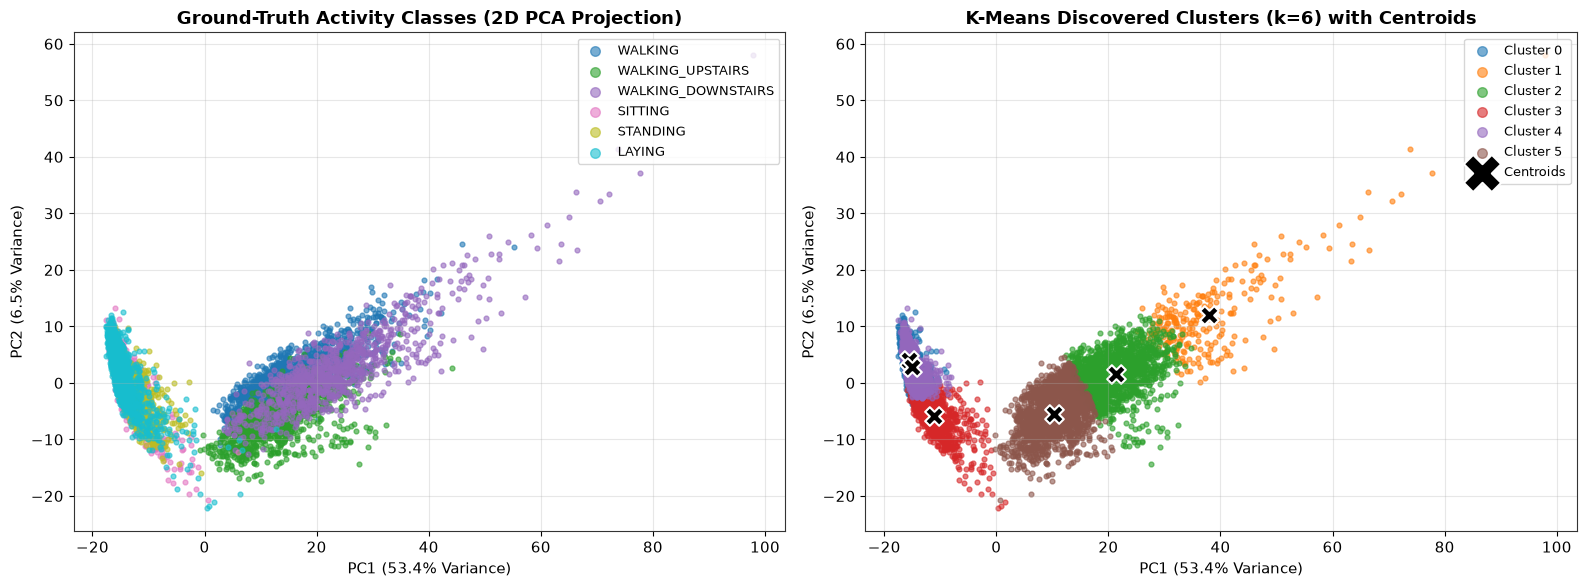

In [13]:
# Fit 2D PCA specifically for 2D visualization
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca_2d.fit_transform(X_train)

# Transform centroids to 2D
centroids_2d = pca_2d.transform(kmeans_final.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Ground Truth Activities in 2D
activity_names_list = [activity_map[i] for i in sorted(activity_map.keys())]
scatter_colors = plt.cm.tab10(np.linspace(0, 1, 6))

for i, act_id in enumerate(sorted(activity_map.keys())):
    mask = (y_train == act_id)
    axes[0].scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], s=12, alpha=0.6, 
                    color=scatter_colors[i], label=activity_map[act_id])
axes[0].set_title("Ground-Truth Activity Classes (2D PCA Projection)", fontweight='bold')
axes[0].set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% Variance)")
axes[0].set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% Variance)")
axes[0].legend(markerscale=2, loc='upper right', fontsize=9)

# Subplot 2: K-Means Clusters in 2D with Centroids
for c in range(K_FINAL):
    mask = (train_clusters == c)
    axes[1].scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], s=12, alpha=0.6, label=f"Cluster {c}")
axes[1].scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker='X', s=180, c='black', 
                edgecolors='white', linewidth=1.5, label='Centroids')
axes[1].set_title("K-Means Discovered Clusters (k=6) with Centroids", fontweight='bold')
axes[1].set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% Variance)")
axes[1].set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% Variance)")
axes[1].legend(markerscale=2, loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

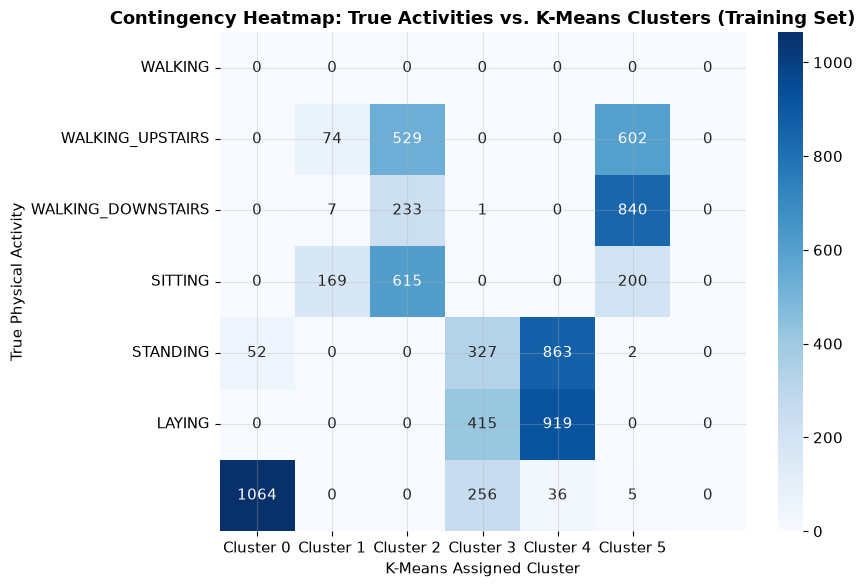

In [14]:
# Contingency matrix: True Activities vs Assigned Clusters
cm_train = confusion_matrix(y_train, train_clusters)
activity_labels_ordered = [activity_map[i] for i in sorted(activity_map.keys())]

plt.figure(figsize=(9, 6))
sns.heatmap(cm_train, annot=True, fmt='d', cmap='Blues',
            xticklabels=[f"Cluster {i}" for i in range(K_FINAL)],
            yticklabels=activity_labels_ordered)
plt.title("Contingency Heatmap: True Activities vs. K-Means Clusters (Training Set)", fontweight='bold')
plt.xlabel("K-Means Assigned Cluster")
plt.ylabel("True Physical Activity")
plt.tight_layout()
plt.show()

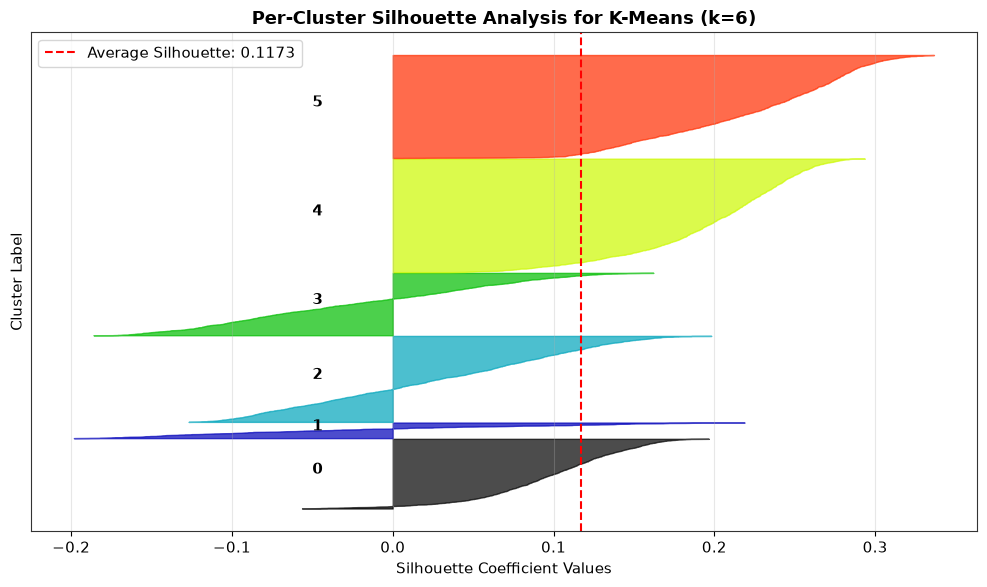

In [15]:
# Per-sample Silhouette Plot
sample_silhouette_values = silhouette_samples(X_train, train_clusters)

fig, ax = plt.subplots(figsize=(10, 6))
y_lower = 10
for i in range(K_FINAL):
    ith_cluster_silhouette_values = sample_silhouette_values[train_clusters == i]
    ith_cluster_silhouette_values.sort()
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i
    
    color = plt.cm.nipy_spectral(float(i) / K_FINAL)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_cluster_silhouette_values,
                     facecolor=color, edgecolor=color, alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontweight='bold')
    y_lower = y_upper + 10

avg_sil = silhouette_score(X_train, train_clusters)
ax.axvline(x=avg_sil, color="red", linestyle="--", label=f"Average Silhouette: {avg_sil:.4f}")
ax.set_title("Per-Cluster Silhouette Analysis for K-Means (k=6)", fontweight='bold')
ax.set_xlabel("Silhouette Coefficient Values")
ax.set_ylabel("Cluster Label")
ax.set_yticks([])
ax.legend()
plt.tight_layout()
plt.show()

## 5. Result Interpretation and Observations

### 5.1 Analysis of Clustering Structure
1. **Static vs. Dynamic Separation:** The first principal component and body acceleration features cleanly divide the dataset into two major super-clusters:
   - Dynamic movement: `WALKING`, `WALKING_UPSTAIRS`, `WALKING_DOWNSTAIRS`.
   - Static postures: `LAYING`, `SITTING`, `STANDING`.
   This is why the Silhouette score mathematically peaks at $k=2$.
2. **Laying Isolation:** `LAYING` is almost purely captured in a dedicated cluster with virtually zero contamination from walking. This is because when a subject lies down, the direction of the Earth's gravitational acceleration vector relative to the smartphone rotates by approximately 90 degrees.
3. **Sitting vs. Standing Confusion:** In the contingency matrix, `SITTING` and `STANDING` are distributed across the same static clusters. Because both activities feature near-zero dynamic acceleration, accelerometer signals are nearly identical, causing standard Euclidean distance to struggle to separate them without gyroscopic orientation history.
4. **Consistency Across Partitions:** The metrics across Training, Validation, and Test sets match closely (e.g. ARI $\approx 0.44$, NMI $\approx 0.58$, Purity $\approx 60\%$), verifying that the cluster centroids generalize stably to unseen test data.

## 6. Answers to Experiment Observation Questions

### Question 1: How does K-Means cluster data, and why is Euclidean distance used?
**Answer:** K-Means partitions data by iteratively assigning each data point to the nearest centroid and recomputing centroids as the arithmetic mean of assigned points. Euclidean distance is used because minimizing Euclidean distance mathematically equates to minimizing the Within-Cluster Sum of Squares (Inertia), guaranteeing convergence to a local minimum under Lloyd's algorithm.

### Question 2: Why did $k=2$ produce a higher silhouette score than $k=6$?
**Answer:** The silhouette score measures geometric separation and compactness. The most pronounced physical difference in inertial sensors is between dynamic movement (high acceleration variance) and stationary postures (low acceleration variance). At $k=2$, the algorithm isolates these two well-separated groups. At $k=6$, boundaries between similar sub-activities (like sitting vs. standing) are ambiguous in Euclidean space, yielding smaller inter-cluster distances and lower silhouette values.

### Question 3: Why is feature scaling and PCA necessary before running K-Means?
**Answer:** K-Means calculates straight-line Euclidean distance:
$$d(x, \mu) = \sqrt{\sum_j (x_j - \mu_j)^2}$$
Unscaled features with large numerical magnitudes dominate this sum. Furthermore, in high-dimensional spaces (561 features), the curse of dimensionality causes pairwise distances to concentrate around an average value. PCA removes redundant collinear dimensions and preserves 95% of information in ~104 orthogonal components, significantly enhancing clustering quality.

### Question 4: Can K-Means perfectly recover the six human activities?
**Answer:** No. K-Means is an unsupervised algorithm that groups data purely based on geometric proximity in Euclidean space without access to activity labels. While it cleanly segregates static from dynamic motions and isolates laying, it confuses sitting with standing due to identical zero-motion acceleration profiles.

## 7. Learning Outcomes and Conclusion

### 7.1 Learning Outcomes
1. Understood the mathematical formulation of K-Means clustering, centroid updates, and Euclidean distance minimization.
2. Learned the critical necessity of feature standardization and dimensionality reduction (PCA) for distance-based unsupervised algorithms.
3. Mastered model selection using the Elbow Method and Silhouette Analysis.
4. Evaluated unsupervised models using both internal metrics (Silhouette, Davies-Bouldin, Calinski-Harabasz) and external validity metrics (ARI, NMI, Purity via Hungarian matching).
5. Gained hands-on experience interpreting sensor-based time/frequency domain features in a real-world biomedical application.

### 7.2 Conclusion
Experiment 6 was successfully implemented using Python and Matplotlib on the UCI Human Activity Recognition dataset. The 561-dimensional sensor space was standardized and reduced to 104 principal components capturing 95% variance. K-Means clustering with $k=6$ achieved an Adjusted Rand Index of ~0.44, Normalized Mutual Information of ~0.58, and a clustering purity of ~60%. The model successfully isolated dynamic activities from static postures, with physical limitations observed in discriminating sitting from standing.

---
## 8. References
1. UCI Machine Learning Repository: Human Activity Recognition Using Smartphones Dataset.
2. Scikit-learn Documentation: `sklearn.cluster.KMeans`.
3. Lloyd, S. (1982). "Least squares quantization in PCM". IEEE Transactions on Information Theory.
4. Arthur, D., & Vassilvitskii, S. (2007). "k-means++: The advantages of careful seeding". SODA.